In [56]:
import pandas as pd

In [57]:
df = pd.DataFrame(
    {
        "Num_flights": [12,20,28,18,29,33,24,45,45,52,51,52,55,53,55,61,64,69,72,],
        "Avg_fare": [39,36,30,52,54,46,55,59,63,70,66,63,58,23,14,8,19,7,24,],
    }
)

In [58]:
#df = df[['Num_flights','Avg_fare']]
df.head()

,Num_flights,Avg_fare
0,12,39
1,20,36
2,28,30
3,18,52
4,29,54


In [59]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3)
kmeans.fit(df)
kmeans.predict(df)

array([2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
      dtype=int32)

In [60]:
sk_centroids = kmeans.cluster_centers_
sk_centroids

array([[62.33333333, 15.83333333],
       [50.        , 63.16666667],
       [23.42857143, 44.57142857]])

In [61]:
kmeans.inertia_

1624.4285714285716

In [62]:
colmap = {1:'r',2:'g',3:'b'}

In [63]:
labels = kmeans.labels_
labels

array([2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
      dtype=int32)

In [64]:
import matplotlib.pyplot as plt

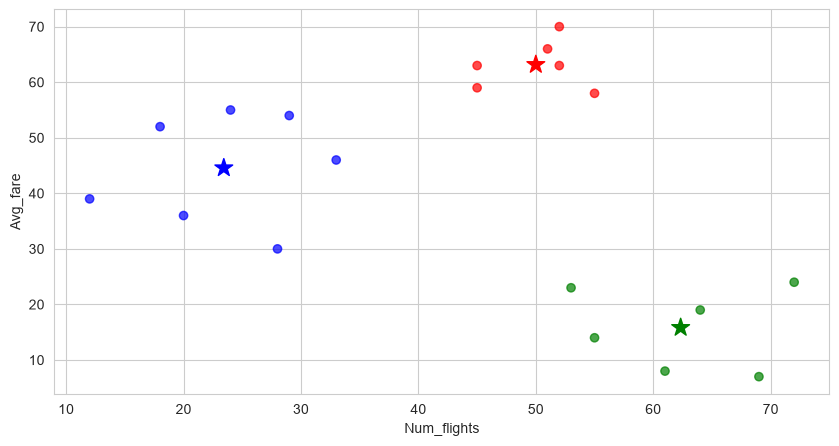

In [40]:
plt.figure(figsize=(10,5))
colors = map(lambda x: colmap[x+1], labels)
color1 = list(colors)
plt.scatter(df['Num_flights'], df['Avg_fare'],color=color1, alpha=0.7)
plt.scatter(sk_centroids[:, 0], sk_centroids[:, 1], marker='*', s=180, c=list(colmap.values()))
plt.xlabel('Num_flights')
plt.ylabel('Avg_fare')
plt.show()

In [41]:
import numpy as np
n = np.arange(1,11)
inertia_list = list()
for num_clusters in n:
  kmeans = KMeans(n_clusters=num_clusters)
  kmeans.fit(df)
  inertia_list.append(kmeans.inertia_)

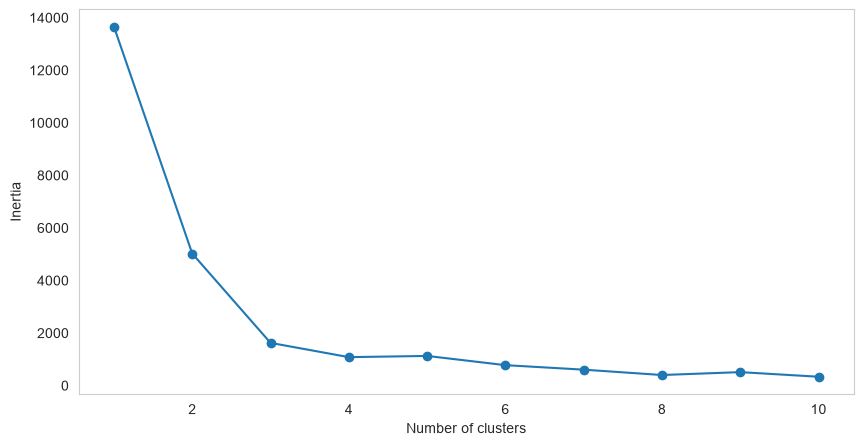

In [42]:
plt.figure(figsize=(10,5))
plt.plot(n,inertia_list,marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.grid()
plt.show()

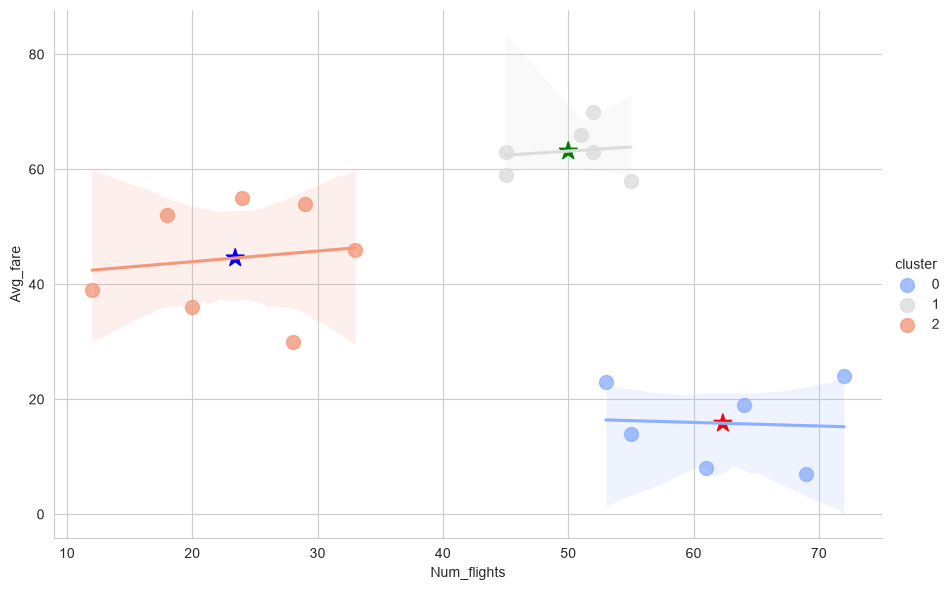

In [70]:
import seaborn as sns

df['cluster'] = kmeans.labels_
sns.set_style('whitegrid')
sns.lmplot(data=df, x='Num_flights', y='Avg_fare', fit_reg=True,palette='coolwarm',hue='cluster',legend=True,scatter_kws={"s": 100},height=6, aspect=1.5)
plt.scatter(sk_centroids[:, 0], sk_centroids[:, 1], marker='*', s=180, c=list(colmap.values()))
plt.show()